In [1]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.device_count()) 
print(torch.cuda.get_device_name())
print(torch.cuda.current_device())



True
2
NVIDIA GeForce RTX 3090
0


In [ ]:
import argparse
import os
import torch
#from exp.exp_main_aa import Exp_Main#exp stands for experiments
import random
#from exp.exp_main import Exp_Main
import numpy as np
from utils.tools import dotdict
import matplotlib.pyplot as plt
import pandas as pd
from autoaugment.policy_search import BasePolicy, RandAugment, TSAA, FastAA
from autoaugment.utils import parse_method_to_policy
%matplotlib inline


fix_seed = 555
#fix_seed = 2021
random.seed(fix_seed)
torch.manual_seed(fix_seed)
np.random.seed(fix_seed)


parser = argparse.ArgumentParser(description='Autoformer & Transformer family for Time Series Forecasting')

# Core parameters
parser.add_argument('--is_training', type=int, default=1, help='1: train, 0: test')
parser.add_argument('--task_id', type=str, default='test', help='task identifier')
parser.add_argument('--model', type=str, default='FEDformer',
                    help='model name: FEDformer, Autoformer, Informer, Transformer, NBEATS_I, NBEATS_G, etc.')

# FEDformer specific parameters
parser.add_argument('--version', type=str, default='Fourier', help='FEDformer version: Fourier or Wavelets')
parser.add_argument('--mode_select', type=str, default='random', help='mode selection method: random or low')
parser.add_argument('--modes', type=int, default=64, help='modes to be selected')
parser.add_argument('--L', type=int, default=3, help='ignore level')
parser.add_argument('--base', type=str, default='legendre', help='mwt base')
parser.add_argument('--cross_activation', type=str, default='tanh', help='cross attention activation')

# Data parameters
parser.add_argument('--data', type=str, default='ETTh1', help='dataset type')
parser.add_argument('--root_path', type=str, default='./dataset/ETT/', help='data root path')
parser.add_argument('--data_path', type=str, default='ETTh1.csv', help='data file name')
parser.add_argument('--features', type=str, default='M',
                    help='forecasting task: M (multivariate->multivariate), S (univariate->univariate), MS (multivariate->univariate)')
parser.add_argument('--target', type=str, default='OT', help='target feature for S or MS task')
parser.add_argument('--freq', type=str, default='h', help='time encoding frequency: s,t,h,d,b,w,m')
parser.add_argument('--checkpoints', type=str, default='./checkpoints/', help='model checkpoint directory')

# Sequence parameters
parser.add_argument('--seq_len', type=int, default=96, help='input sequence length')
parser.add_argument('--label_len', type=int, default=48, help='start token length')
parser.add_argument('--pred_len', type=int, default=96, help='prediction sequence length')

# Model architecture parameters
parser.add_argument('--embed_type', type=int, default=0, help='embedding type')
parser.add_argument('--enc_in', type=int, default=7, help='encoder input size')
parser.add_argument('--dec_in', type=int, default=7, help='decoder input size')
parser.add_argument('--c_out', type=int, default=7, help='output size')
parser.add_argument('--d_model', type=int, default=512, help='dimension of model')
parser.add_argument('--n_heads', type=int, default=8, help='num of attention heads')
parser.add_argument('--e_layers', type=int, default=2, help='num of encoder layers')
parser.add_argument('--d_layers', type=int, default=1, help='num of decoder layers')
parser.add_argument('--d_ff', type=int, default=2048, help='dimension of fcn')
parser.add_argument('--moving_avg', default=[24], help='moving average window size')
parser.add_argument('--factor', type=int, default=1, help='attention factor')
parser.add_argument('--distil', action='store_false', default=True, help='whether to use distilling in encoder')
parser.add_argument('--dropout', type=float, default=0.05, help='dropout rate')
parser.add_argument('--embed', type=str, default='timeF', help='time encoding: timeF, fixed, learned')
parser.add_argument('--activation', type=str, default='gelu', help='activation function')
parser.add_argument('--output_attention', action='store_true', help='output attention weights')
parser.add_argument('--do_predict', action='store_true', help='predict on unseen future data')

# Training parameters
parser.add_argument('--num_workers', type=int, default=10, help='data loader workers')
parser.add_argument('--itr', type=int, default=3, help='experiment iterations')
parser.add_argument('--train_epochs', type=int, default=10, help='train epochs')
parser.add_argument('--batch_size', type=int, default=32, help='batch size')
parser.add_argument('--patience', type=int, default=3, help='early stopping patience')
parser.add_argument('--learning_rate', type=float, default=0.0001, help='optimizer learning rate')
parser.add_argument('--loss', type=str, default='mse', help='loss function')
parser.add_argument('--lradj', type=str, default='type1', help='learning rate adjustment')
parser.add_argument('--use_amp', action='store_true', help='use automatic mixed precision')
parser.add_argument('--pct_start', type=float, default=0.3, help='pct_start for scheduler')
parser.add_argument('--weight_decay', type=float, default=0, help='weight decay')

# Model specific parameters
# DLinear
parser.add_argument('--individual', action='store_true', default=False, help='DLinear: individual layer per variate')

# PatchTST
parser.add_argument('--fc_dropout', type=float, default=0.05, help='fully connected dropout')
parser.add_argument('--head_dropout', type=float, default=0.0, help='head dropout')
parser.add_argument('--patch_len', type=int, default=16, help='patch length')
parser.add_argument('--stride', type=int, default=8, help='stride')
parser.add_argument('--padding_patch', default='end', help='padding type: None or end')
parser.add_argument('--revin', type=int, default=1, help='RevIN normalization')
parser.add_argument('--affine', type=int, default=0, help='RevIN-affine')
parser.add_argument('--subtract_last', type=int, default=0, help='subtract method: mean or last')
parser.add_argument('--decomposition', type=int, default=0, help='decomposition flag')
parser.add_argument('--kernel_size', type=int, default=25, help='decomposition kernel size')

# N-BEATS
parser.add_argument('--nb_layers', type=int, default=4, help='NBEATS layers')
parser.add_argument('--nb_layer_size', type=int, default=512, help='NBEATS layer size')
parser.add_argument('--nb_stacks', type=int, default=30, help='NBEATS stacks')
parser.add_argument('--nb_seasonality_layer_size', type=int, default=2048, help='NBEATS seasonality layer size')
parser.add_argument('--nb_seasonality_blocks', type=int, default=3, help='NBEATS seasonality blocks')
parser.add_argument('--nb_seasonality_layers', type=int, default=4, help='NBEATS seasonality layers')
parser.add_argument('--nb_trend_layer_size', type=int, default=256, help='NBEATS trend layer size')
parser.add_argument('--nb_degree_of_polynomial', type=int, default=3, help='NBEATS polynomial degree')
parser.add_argument('--nb_trend_blocks', type=int, default=3, help='NBEATS trend blocks')
parser.add_argument('--nb_trend_layers', type=int, default=4, help='NBEATS trend layers')
parser.add_argument('--nb_num_of_harmonics', type=int, default=1, help='NBEATS harmonics')

# Hardware
parser.add_argument('--use_gpu', type=bool, default=True, help='use GPU')
parser.add_argument('--gpu', type=int, default=0, help='GPU index')
parser.add_argument('--use_multi_gpu', action='store_true', default=False, help='use multiple GPUs')
parser.add_argument('--devices', type=str, default='0,1', help='device IDs of multiple GPUs')

# AutoAugment
parser.add_argument('--stl', type=bool, default=True, help='use STL decomposition')
parser.add_argument('--seasonality', type=int, default=12, help='seasonality parameter')
parser.add_argument('--method', type=str, default="TSAA", help='augmentation method: TSAA, FastAA, randaugment')
parser.add_argument('--n_aug_ratio', default=0.5, type=float, help='augmentation ratio')
parser.add_argument('--random_seed_aa', type=int, default=fix_seed, help='augmentation seed')
parser.add_argument('--random_seed_model', type=int, default=fix_seed, help='model seed')
parser.add_argument('--early_stopping_aa', type=bool, default=True, help='early stopping for augmented training')
parser.add_argument('--device_name', type=str, default=torch.cuda.get_device_name() if torch.cuda.is_available() else 'cpu', help='device name')
parser.add_argument('--save_baseline', type=bool, default=False, help='save baseline model')
parser.add_argument('--save_aug', type=bool, default=False, help='save augmented model')
parser.add_argument('--search', type=str, default="TPE", help='search method: TPE or random')
parser.add_argument('--save_predict', type=bool, default=False, help='save predictions')
parser.add_argument('--n_trials', type=int, default=100, help='number of search trials')
parser.add_argument('--kfold', type=int, default=3, help='folds for cross-validation')

# Logging
parser.add_argument('--full_monitor', type=bool, default=True, help='monitor full training')
parser.add_argument('--trials_log', type=bool, default=True, help='log trial info')
parser.add_argument('--optuna_log', type=bool, default=True, help='log optuna info')
parser.add_argument('--use_logger', type=bool, default=True, help='use logger')

# TimeMixer and other models
parser.add_argument('--task_name', type=str, default='long_term_forecast', help='task type')
parser.add_argument('--seasonal_patterns', type=str, default='Monthly', help='M4 subset')
parser.add_argument('--inverse', action='store_true', default=False, help='inverse output data')
parser.add_argument('--top_k', type=int, default=5, help='TimesBlock parameter')
parser.add_argument('--num_kernels', type=int, default=6, help='Inception parameter')
parser.add_argument('--channel_independence', type=int, default=1, help='channel independence flag')
parser.add_argument('--decomp_method', type=str, default='moving_avg', help='decomposition method')
parser.add_argument('--use_norm', type=int, default=1, help='normalization flag')
parser.add_argument('--down_sampling_layers', type=int, default=0, help='downsampling layers')
parser.add_argument('--down_sampling_window', type=int, default=1, help='downsampling window')
parser.add_argument('--down_sampling_method', type=str, default='avg', help='downsampling method')

# Projector parameters
parser.add_argument('--p_hidden_dims', type=int, nargs='+', default=[128, 128], help='projector hidden dimensions')
parser.add_argument('--p_hidden_layers', type=int, default=2, help='projector hidden layers')

# Misc
parser.add_argument('--des', type=str, default='test', help='experiment description')
parser.add_argument('--override_table', type=bool, default=False, help='override results table')
parser.add_argument('--comment', type=str, default='none', help='additional comments')



args = parser.parse_args("\
  --is_training 1 \
  --root_path ./dataset/illness/ \
  --data_path national_illness.csv \
  --task_id ili \
  --model Autoformer \
  --data custom_aa \
  --features M \
  --seq_len 36 \
  --label_len 18 \
  --pred_len 24 \
  --e_layers 2 \
  --d_layers 1 \
  --factor 3 \
  --enc_in 7 \
  --dec_in 7 \
  --c_out 7 \
  --des 'Exp' \
  --itr 1\
  --seasonality 52".split()) 

                        
args

Namespace(is_training=1, task_id='ili', model='Autoformer', version='Fourier', mode_select='random', modes=64, L=3, base='legendre', cross_activation='tanh', data='custom_aa', root_path='./dataset/illness/', data_path='national_illness.csv', features='M', target='OT', freq='h', checkpoints='./checkpoints/', seq_len=36, label_len=18, pred_len=24, embed_type=0, enc_in=7, dec_in=7, c_out=7, d_model=512, n_heads=8, e_layers=2, d_layers=1, d_ff=2048, moving_avg=[24], factor=3, distil=True, dropout=0.05, embed='timeF', activation='gelu', output_attention=False, do_predict=False, num_workers=10, itr=1, train_epochs=10, batch_size=32, patience=3, learning_rate=0.0001, des="'Exp'", loss='mse', lradj='type1', use_amp=False, pct_start=0.3, weight_decay=0, individual=False, fc_dropout=0.05, head_dropout=0.0, patch_len=16, stride=8, padding_patch='end', revin=1, affine=0, subtract_last=0, decomposition=0, kernel_size=25, nb_layers=4, nb_layer_size=512, nb_stacks=30, nb_seasonality_layer_size=2048, 

In [ ]:
"""
#args.dropout = 0.1
#args.checkpoints = "/cs_groups/azencot_group/TSAA/checkpoints"
args.save_baseline = True
args.save_aug = True
args.repeat = 2
args.method = 'ensemble'
args.full_monitor = False
args.full_train = True
"""
args.n_aug_ratio = 0.5
#args.inference = True


#args.pred_len = 33
#args.weight_decay = 1e-4
#args.method = 'dropout'
args.method = 'TSAA'
args.method = 'randaugment'
args.method = 'TSAA'
args.method = "Smooth_1.0_Jittering_0.5"
args.k_fold =  3
n_aug_ratio = 0.3
#n_trials = 7
#args.train_epochs = 3

args.n_trials = 25
#args.method = 'TSAA'
#args.method = 'direct'
args.itr = 1

args.override_table = True



In [ ]:


df = pd.DataFrame( columns = ["complete","itr","method","model","dataset","pred_len", "seed","final_mse","final_mae","baseline_mse","baseline_mae", "policy"])
#folder_path = os.getcwd()+'/table_monitor/'
folder_path = os.getcwd()+'/table_monitor_sandbox/'
table_id_name = '{}_{}_{}_modes{}_{}_ft{}_sl{}_ll{}_pl{}_{}_{}_{}_exp'.format(
        args.task_id,
        args.model,
        args.mode_select,
        args.modes,
        args.data,
        args.features,
        args.seq_len,
        args.label_len,
        args.pred_len,
        args.method, 
        args.search,
        args.n_aug_ratio)

table_path = folder_path+table_id_name+'.csv'

# check of table exists
if os.path.isfile(table_path) and not args.override_table:
    print("openinig experiment: ", table_id_name)
    df = pd.read_csv(table_path)

else: 
    if args.override_table:
        print("overriding experiment: ", table_id_name)
    else:
        print("creating experiment: ", table_id_name)
    if not os.path.exists(folder_path):
        os.makedirs(folder_path) 
    df.to_csv(table_path,index=False)

print()
print("##### start training #####")

overriding experiment:  ili_Autoformer_random_modes64_custom_aa_ftM_sl36_ll18_pl24_Smooth_1.0_Jittering_0.5_TPE_0.5_exp

##### start training #####


>>>>>>>start training : ili_Autoformer_random_modes64_custom_aa_ftM_sl36_ll18_pl24_1_Smooth_1.0_Jittering_0.5_TPE_0.5_exp>>>>>>>>>>>>>>>>>>>>>>>>>>
Use GPU: cuda:0
Autocorrelation used !
Autocorrelation used !
Autocorrelation used !
Autocorrelation used !
import stl
import successful
Saving checkpoint...
Checkpoint saved in 0.20 seconds
Epoch: 1 cost time: 1.281360387802124
Epoch: 1, Steps: 19 | Train Loss: 1.0116537 Vali Loss: 0.7846661 Test Loss: 4.4913092
Validation loss decreased (inf --> 0.784666).  Saving model ...
Saving checkpoint...
Checkpoint saved in 0.36 seconds
Epoch: 2 cost time: 0.892509937286377
Epoch: 2, Steps: 19 | Train Loss: 0.6614512 Vali Loss: 0.5136362 Test Loss: 3.9322457
Validation loss decreased (0.784666 --> 0.513636).  Saving model ...
Saving checkpoint...
Checkpoint saved in 0.37 seconds
Epoch: 3 cost time: 0.8978326320648193
Epoch: 3, Steps: 19 | Train Loss: 0.5436662 Vali Loss: 0.3819373 Test Loss: 3.7849884
Validation loss decreased (0.513636 --> 0.38193

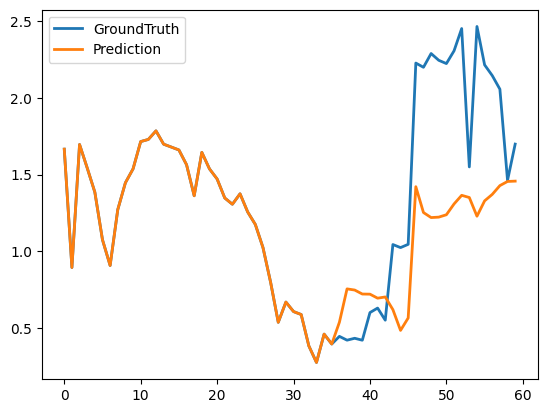

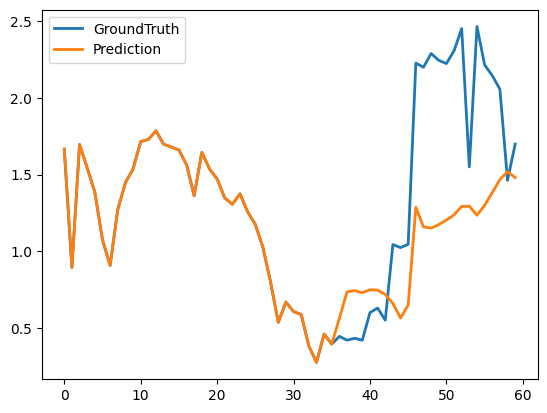

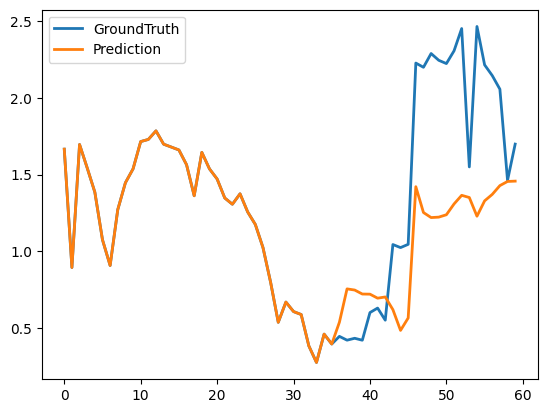

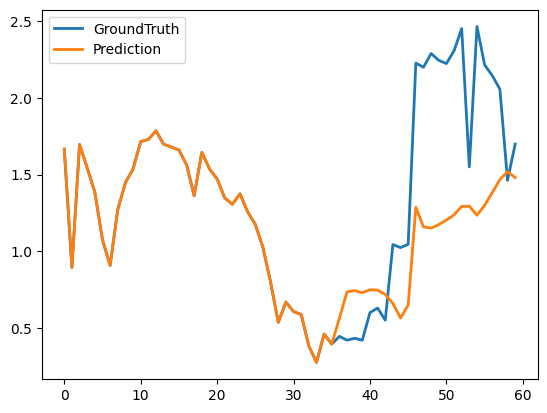

In [6]:
for ii in range(args.itr):
    # Skip completed experiments
    if len(df[(df['itr'] == ii) & (df['complete'] == True)]) > 0:
        print(f"experiment completed, skipping iteration: {ii}")
        continue

    # Set random seed and create setting string
    args.random_seed_aa = ii * args.random_seed_aa + 1
    setting = f'{args.task_id}_{args.model}_{args.mode_select}_modes{args.modes}_{args.data}_ft{args.features}_sl{args.seq_len}_ll{args.label_len}_pl{args.pred_len}_{args.random_seed_aa}_{args.method}_{args.search}_{args.n_aug_ratio}_exp'
    
    # Create and run appropriate policy based on method
    if args.method == "TSAA":
        pipeline_policy = TSAA(args=args, search=args.search, n_trials=args.n_trials)
    elif args.method == "FastAA":
        pipeline_policy = FastAA(args=args, n_trials=args.n_trials, method=args.method)
    elif args.method == "randaugment":
        pipeline_policy = RandAugment(args=args, method=args.method)
    else:
        policy = parse_method_to_policy(args.method)
        pipeline_policy = BasePolicy(args=args, method=args.method, policy=policy)
    
    # Train and test with the selected policy
    print(f'>>>>>>>start training : {setting}>>>>>>>>>>>>>>>>>>>>>>>>>>')
    pipeline_policy.train(setting, remove_checkpoints=True)
    print(f'>>>>>>>testing : {setting}<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<')
    pipeline_policy.test(setting)

    # Record results
    log_info = pipeline_policy.log_info
    row = [
        True, ii, args.method, args.model, args.task_id, args.pred_len, 
        args.random_seed_aa, log_info["final_mse"], log_info["final_mae"],
        log_info["baseline_mse"], log_info["baseline_mae"], pipeline_policy.final_policy
    ]
    df.loc[len(df)] = row
    df.to_csv(table_path, index=False)